# Image-domain exercises: EfficientNet backbone, pooling heads, augmentation

This notebook is a self-contained set of exercises on **image models** built around a
frozen, pretrained `EfficientNet-B0` backbone loaded via `timm`. Everything runs on
**CPU** with small data subsets, so total compute is a few minutes (the one-time
dataset/weight downloads may take longer).

Exercises:

1. **Backbone + pooling heads** — compare three ways of turning a spatial feature map
   into a single vector for classification: global average pooling (baseline), global
   min/max pooling .
2. **Data augmentation** — see how random crops/flips/rotations/color jitter affect
   training on a tiny dataset.


Task 1 and 2 use a cat/dog subset of **CIFAR-10**. 

In [22]:
%pip install -q torch torchvision matplotlib pandas pyarrow timm

import os, io, time, random, hashlib, pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
from torchvision import transforms
import timm
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")
DATA_ROOT = "./data"
os.makedirs(DATA_ROOT, exist_ok=True)

# A small, fixed categorical palette used consistently for every chart below
# (identity -> color, in a fixed order; never re-cycled between plots).
PALETTE = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a"}
MUTED, GRID = "#898781", "#e1e0d9"

def style_ax(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

print("device:", device)


Note: you may need to restart the kernel to use updated packages.
device: cpu


## Data: CIFAR-10, cat vs. dog

We use `torchvision.datasets.CIFAR10`, restricted to the **cat** and **dog** classes,
then subsampled to a small working set (~300 train / ~100 valid images) so everything
trains quickly on CPU. We then write those images out as real JPEG files and build a
`pandas` manifest (`image_path`, `label`) instead of wrapping the `CIFAR10`/`Subset`
objects directly — the same file-path-driven shape you'd use for any other image
classification dataset.

**Loading the raw CIFAR-10 pickles:**

1. **Kaggle input** — This notebook is running on Kaggle with the
   [`cifar10-python`](https://www.kaggle.com/datasets/pankrzysiu/cifar10-python) dataset
   attached, it's already mounted read-only at
   `/kaggle/input/cifar10-python/cifar-10-batches-py/` in the original
   `cifar-10-batches-py` pickle layout — no download needed at all.



In [23]:
def point_cifar10_at_pickles(dirpath, train_batches=("data_batch_1", "data_batch_2",
                                                       "data_batch_3", "data_batch_4", "data_batch_5")):
    '''Patch torchvision.datasets.CIFAR10's expected checksums to match whatever
    data_batch_*/test_batch/batches.meta files are actually on disk at dirpath, so
    download=False loads them with no network access and no re-copying (used for a
    Kaggle-mounted, read-only copy of the dataset, or for the single-batch HF mirror
    below via a narrower train_batches).'''
    train_list = [[fname, hashlib.md5(open(os.path.join(dirpath, fname), "rb").read()).hexdigest()]
                  for fname in train_batches]
    test_list = [["test_batch",
                  hashlib.md5(open(os.path.join(dirpath, "test_batch"), "rb").read()).hexdigest()]]
    meta_md5 = hashlib.md5(open(os.path.join(dirpath, "batches.meta"), "rb").read()).hexdigest()
    torchvision.datasets.CIFAR10.train_list = train_list
    torchvision.datasets.CIFAR10.test_list = test_list
    torchvision.datasets.CIFAR10.meta = {"filename": "batches.meta", "key": "label_names", "md5": meta_md5}

# Prefer a Kaggle-mounted copy (no network at all) when this notebook runs on Kaggle
# with the `cifar10-python` dataset attached; 
KAGGLE_CIFAR_DIR = "/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py"

t0 = time.time()
if os.path.isdir(KAGGLE_CIFAR_DIR):
    point_cifar10_at_pickles(KAGGLE_CIFAR_DIR)
    cifar_root = os.path.dirname(KAGGLE_CIFAR_DIR)
    cifar_train = torchvision.datasets.CIFAR10(root=cifar_root, train=True, download=False)
    cifar_valid_full = torchvision.datasets.CIFAR10(root=cifar_root, train=False, download=False)
    print(f"CIFAR-10 loaded from Kaggle input in {time.time()-t0:.1f}s | classes={cifar_train.classes}")


CIFAR-10 loaded from Kaggle input in 1.7s | classes=['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [24]:
cifar_train.classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

## Question
* Check the stats of the dataset
* How many samples exist per category.


In [25]:
print(cifar_train)
print(len(cifar_train))
print(cifar_train.class_to_idx)

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: /kaggle/input/datasets/pankrzysiu/cifar10-python
    Split: Train
50000
{'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


In [26]:
print(type(cifar_train.data))  
print(cifar_train.data.shape) 
print(cifar_train.data.dtype)

<class 'numpy.ndarray'>
(50000, 32, 32, 3)
uint8


In [27]:
counts = Counter(cifar_train.targets)

for label, class_name in enumerate(cifar_train.classes):
    print(f"{class_name}: {counts[label]}")

airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000


train_subset=300  valid_subset=100
train_df=300  test_df=100


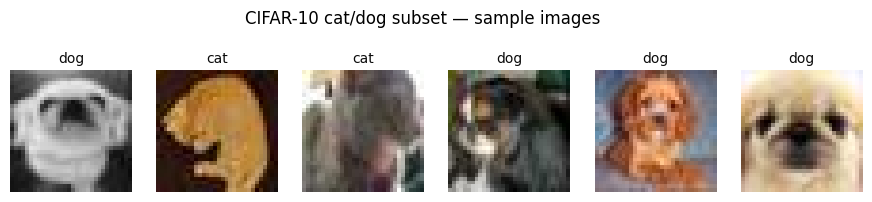

In [28]:
CAT, DOG = cifar_train.class_to_idx["cat"], cifar_train.class_to_idx["dog"]

def filter_and_subsample(dataset, n_per_class, seed=SEED):
    rng = np.random.RandomState(seed)
    idx_cat = np.array([i for i, t in enumerate(dataset.targets) if t == CAT])
    idx_dog = np.array([i for i, t in enumerate(dataset.targets) if t == DOG])
    idx_cat = rng.choice(idx_cat, min(n_per_class, len(idx_cat)), replace=False)
    idx_dog = rng.choice(idx_dog, min(n_per_class, len(idx_dog)), replace=False)
    idx = np.concatenate([idx_cat, idx_dog])
    rng.shuffle(idx)
    return Subset(dataset, idx.tolist())

train_subset = filter_and_subsample(cifar_train, 150)       # ~150 cat and 150 dogs total = 300 images
valid_subset = filter_and_subsample(cifar_valid_full, 50)   
print(f"train_subset={len(train_subset)}  valid_subset={len(valid_subset)}")

# Materialize the cat/dog subset to real JPEG files + a pandas manifest, so the rest of
# this notebook can use a plain image-path-driven Dataset (CustomTrainingData below)
# instead of wrapping CIFAR10/Subset objects directly.
CATDOG_ROOT = os.path.join(DATA_ROOT, "catdog")
CLASS_LIST = ["cat", "dog"]

def materialize_to_disk(subset, split):
    split_dir = os.path.join(CATDOG_ROOT, split)
    os.makedirs(split_dir, exist_ok=True)
    rows = []
    for i, (img, t) in enumerate(subset):
        label = "cat" if t == CAT else "dog"
        path = os.path.join(split_dir, f"{i:03d}_{label}.jpg")
        img.save(path)
        rows.append({"image_path": path, "label": label})
    return pd.DataFrame(rows)

train_df = materialize_to_disk(train_subset, "train")
test_df = materialize_to_disk(valid_subset, "test")
print(f"train_df={len(train_df)}  test_df={len(test_df)}")

fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
for ax, (_, row) in zip(axes, train_df.sample(6, random_state=SEED).iterrows()):
    ax.imshow(Image.open(row.image_path))
    ax.set_title(row.label, fontsize=10, color="#0b0b0b")
    ax.axis("off")
fig.suptitle("CIFAR-10 cat/dog subset — sample images", y=1.05)
plt.show()


## Exercise 1 — EfficientNet backbone + custom pooling heads

We build a classifier on top of a pretrained backbone the standard way: a `timm`
model plus a small trainable head, defined in `CustomTimmModel` below. The backbone
is loaded with `global_pool=''` so it keeps its **spatial** feature map
`[B, C, H, W]`, and pooling that map down to a single vector before the head is one
explicit line inside `forward` — there's more than one reasonable way to write that
line.

We compare three pooling strategies, each its own small model class that differs from
`CustomTimmModel` *only* in that one line 

1. **`CustomTimmModel`** — global *average* pooling (the standard baseline).
2. **`MinPoolTimmModel`** — global *min* pooling (negate → adaptive max pool → negate back).
3. **`MaxPoolTimmModel`** - global *max* pooling (to be implemented)


"Frozen backbone" here just means calling `model.backbone.requires_grad_(False)` (and
`.eval()`) on an instance before training it, so the optimizer's `filter(lambda p:
p.requires_grad, ...)` naturally skips the backbone and only updates the head (and any
extra pooling parameters)

In [29]:
import torch.nn.functional as F

In [30]:
IMG_SIZE = 96
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] #Normalization values for RGB channels coming from imagenet 

base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD), # every image needs to be normalized to imagenet normalization values (standardized on 1.2m images)
])

# Define custom Dataset -> this will help you load images from your csv file
class CustomTrainingData(Dataset):
    def __init__(self, csv_df, class_list, transform=None):
        self.df = csv_df
        self.transform = transform
        self.class_list = class_list

    def __len__(self):
        return self.df.shape[0]

    def __getitem__(self, index):
        image = Image.open(self.df.iloc[index].image_path).convert('RGB')
        label = self.class_list.index(self.df.iloc[index].label)

        if self.transform:
            image = self.transform(image)

        return image, label

train_data_object = CustomTrainingData(train_df, CLASS_LIST, base_transform)
test_data_object = CustomTrainingData(test_df, CLASS_LIST, base_transform)

BATCH_SIZE = 32

# now define dataloader, this will load the images batches from CustomTrainingData object
# num_workers=0: on macOS, ipykernel/nbconvert's "spawn" multiprocessing start method
# can't re-import notebook-defined classes (CustomTrainingData) in worker processes,
# so num_workers>0 here crashes with a pickling error. num_workers=0 loads in-process.
train_loader = DataLoader(train_data_object, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data_object, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# The pattern: a timm backbone (global_pool='' keeps the spatial map) + a small
# trainable head. Pooling is the one explicit line in forward -- change that line to
# try a different pooling strategy (see MinPoolTimmModel / AttentionPoolTimmModel below).
class CustomTimmModel(nn.Module):
    def __init__(self, model_name='resnet50', num_classes=10, pretrained=True):
        super().__init__()

        # 1. Load the backbone as a feature extractor (num_classes=0 removes the
        #    original head; global_pool='' keeps the spatial map instead of pooling it)
        self.backbone = timm.create_model(model_name, pretrained=pretrained,
                                           num_classes=0, global_pool='')

        # 2. Get the number of input features for your head dynamically
        num_features = self.backbone.num_features

        # 3. Define your custom sequential head
        self.head = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        # Extract the spatial feature map from the backbone
        features = self.backbone.forward_features(x)
        # Pool [B, C, H, W] -> [B, C]: global average pooling (the baseline)
        pooled = F.adaptive_avg_pool2d(features, 1).flatten(1)
        # Pass pooled features through your custom sequential head
        out = self.head(pooled)
        return out

# Quick smoke test: confirm the pattern runs end-to-end on one batch, before we dig
# into the pooling-strategy comparison below.
baseline_model = CustomTimmModel(model_name='efficientnet_b0', num_classes=2, pretrained=True)
sample_images, sample_labels = next(iter(train_loader))
with torch.no_grad():
    sample_out = baseline_model(sample_images)
print("CustomTimmModel output shape:", tuple(sample_out.shape))


CustomTimmModel output shape: (32, 2)


In [31]:
sample_images.data.shape

torch.Size([32, 3, 96, 96])

In [32]:
class MinPoolTimmModel(CustomTimmModel):
    '''Identical to CustomTimmModel -- only forward's pooling line changes.'''
    def forward(self, x):
        features = self.backbone.forward_features(x)
        # negate -> adaptive max pool -> negate back = min
        pooled = (-F.adaptive_max_pool2d(-features, 1)).flatten(1)
        out = self.head(pooled)
        return out

class MaxPoolTimmModel(CustomTimmModel):
    '''Identical to CustomTimmModel -- only forward's pooling line changes.'''
    def forward(self, x):
        features = self.backbone.forward_features(x)
        pooled = (F.adaptive_max_pool2d(features, 1)).flatten(1)
        out = self.head(pooled)
        return out


def train_model(model, train_loader, valid_loader, epochs=3, lr=1e-3):
    # Which params get updated is controlled entirely by requires_grad: call
    # model.backbone.requires_grad_(False) before training for the frozen-backbone
    # case (used below), or leave it as-is to fine-tune the whole model.
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train_loss": [], "valid_loss": [], "valid_acc": []}
    for epoch in range(epochs):
        # Training
        model.train()
        total, n = 0.0, 0
        for images, labels in train_loader:
            opt.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            opt.step()
            total += loss.item() * len(labels); n += len(labels)

        # Validation
        model.eval()
        all_predictions, all_labels = [], []
        vtotal, vn = 0.0, 0
        with torch.no_grad():
            for images, labels in valid_loader:
                outputs = model(images)
                vtotal += loss_fn(outputs, labels).item() * len(labels); vn += len(labels)
                _, predicted = torch.max(outputs.data, 1)
                all_predictions.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        vacc = float((np.array(all_predictions) == np.array(all_labels)).mean())
        history["train_loss"].append(total / n)
        history["valid_loss"].append(vtotal / vn)
        history["valid_acc"].append(vacc)
    return history

In [33]:
pooling_strategies = {"GAP": CustomTimmModel, "MinPool": MinPoolTimmModel, "MaxPool" : MaxPoolTimmModel}

histories, models = {}, {}
t0 = time.time()
for name, ModelClass in pooling_strategies.items():
    torch.manual_seed(SEED)
    model = ModelClass(model_name='efficientnet_b0', num_classes=2, pretrained=True)
    model.backbone.requires_grad_(False)
    model.backbone.eval()
    histories[name] = train_model(model, train_loader, test_loader, epochs=3)
    models[name] = model
    print(f"{name:<10} final valid_acc={histories[name]['valid_acc'][-1]:.3f}")
print(f"Trained 3 pooling heads in {time.time()-t0:.1f}s")

GAP        final valid_acc=0.620
MinPool    final valid_acc=0.490
MaxPool    final valid_acc=0.690
Trained 3 pooling heads in 28.6s


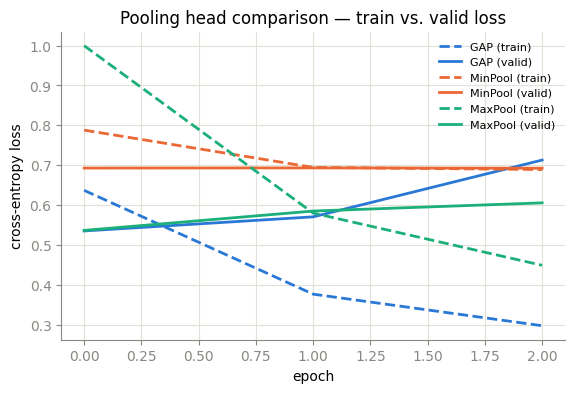

Head           Final valid acc
GAP                      0.620
MinPool                  0.490
MaxPool                  0.690

Best-performing head: MaxPool


In [34]:
colors = {"GAP": PALETTE["blue"], "MinPool": PALETTE["orange"], "MaxPool": PALETTE["aqua"]}

fig, ax = plt.subplots(figsize=(6.5, 4))
for name, h in histories.items():
    ax.plot(h["train_loss"], color=colors[name], linestyle="--", linewidth=2,
             label=f"{name} (train)")
    ax.plot(h["valid_loss"], color=colors[name], linestyle="-", linewidth=2,
             label=f"{name} (valid)")
style_ax(ax)
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
ax.set_title("Pooling head comparison — train vs. valid loss")
ax.legend(fontsize=8, frameon=False, ncol=1)
plt.show()

print(f"{'Head':<12}{'Final valid acc':>18}")
for name, h in histories.items():
    print(f"{name:<12}{h['valid_acc'][-1]:>18.3f}")

best_head_name = max(histories, key=lambda k: histories[k]["valid_acc"][-1])
print(f"\nBest-performing head: {best_head_name}")


## Questions

* What is dataloader
* What is the effect of batch size value, 
* In the cell above what is the shape of sample_images, what does each dimension represent?
* Increase the number of training data and see the effect on the train/validation loss


## Answers
* Data loader is a tool for loading and manipulating data integrated in PyTorch. It has features to enable Bathcing, Shuffling and Processing of the data for use in ML.
* Batch size sets the amount of data points to processed in parallel. By using smaller batch numbers, the memory used at any one time in training is reduced, enabling training on larger datasets on memory constrained machines, at the cost of extra runtime.
* 32 -> no of images, 3 -> colour channels, 96,96 -> size of the upscaled images in pixels
* 150 image scores: GAP=0.62, MinPool=0.49; 300 image scores: GAP=0.65, MinPool=0.5


## Questions:
* Implement a new class similar to MinPoolTimmModel for max pooling.
* Observe the training and validation loss
* Compare the result with the currently implemented pooling heads.
* Check on the web what is the default pooling layer of the timm model
* Report your observations on the above questions

## Answers
* GAP: TrainLoss=0.3, ValidLoss=0.71, MinPool: TrainLoss=0.7, ValidLoss=0.7, MaxPool: TrainLoss=0.45, ValidLoss=0.6
* MaxPool achieves a greater accuracy of 0.69, which is an improvement over the existing pools.
* Default pooling type of the timm model is 'avg', average.

### Full fine-tuning vs. a frozen backbone

Above, we froze the backbone by calling `model.backbone.requires_grad_(False)` before
training, so `train_model`'s `filter(lambda p: p.requires_grad, ...)` only ever
updates the head. If we skip that call, every backbone parameter still has
`requires_grad=True`, so the same optimizer line now updates the backbone's conv
layers too — a full fine-tune instead of head-only training. 


In [35]:
torch.manual_seed(SEED)
finetune_model = CustomTimmModel(model_name='efficientnet_b0', num_classes=2, pretrained=True)
# No requires_grad_(False) call here -> every parameter stays trainable -> full fine-tune.

t0 = time.time()
finetune_history = train_model(finetune_model, train_loader, test_loader, epochs=3, lr=1e-4)
print(f"Full fine-tune         final valid_acc={finetune_history['valid_acc'][-1]:.3f} "
      f"(trained in {time.time()-t0:.1f}s)")
print(f"Frozen backbone ({best_head_name} head) final valid_acc="
      f"{histories[best_head_name]['valid_acc'][-1]:.3f}")

Full fine-tune         final valid_acc=0.750 (trained in 25.2s)
Frozen backbone (MaxPool head) final valid_acc=0.690


# Questions 
* What could be the downsides of doing fine tuning of a pretrained model

## Answers
* Risk of overfitting
* Increase in training time
* Could damage pre-trained weights

## Exercise 2 — Data augmentation

**Motivation:** a model that only ever sees one canonical view of a cat learns
shortcuts, not "catness". Augmentation — random crops, flips, rotations, color
jitter — forces the model to recognize the *same subject* across different
perspectives, framings, and lighting, which is a proxy for the variation it will meet
in the real world. The result should be a model that's more robust, at the cost of a
harder training signal.

Below we build an augmented pipeline (`RandomResizedCrop`, `RandomHorizontalFlip`,
`RandomRotation`, `ColorJitter`) vs. a plain resize-only baseline, visualize what the
augmentations actually do to one image, and then retrain the best pooling head from
Exercise 1 with and without augmentation — reusing the exact same `CustomTrainingData`
/ `DataLoader` / model / training-loop code from Exercise 1, just swapping the
transform.


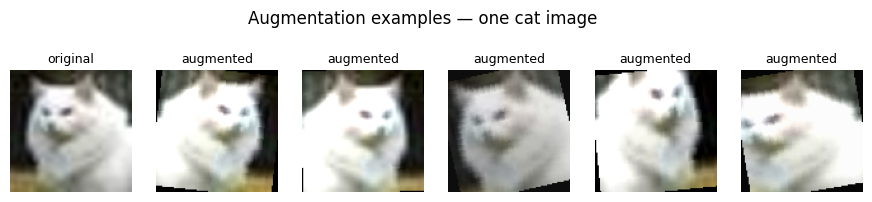

In [36]:
from torchvision.transforms import v2
from torch.utils.data import default_collate

cutmix = v2.CutMix(num_classes=2)
mixup = v2.MixUp(num_classes=2)

cutmix_or_mixup = v2.RandomChoice([cutmix, mixup])

def collate_with_mixing(batch):
    images, labels = default_collate(batch)
    return cutmix_or_mixup(images, labels)

aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
# PIL-only version (no normalize) purely for visualization, so colors look natural
aug_display = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
])

sample_row = train_df.iloc[0]
sample_img = Image.open(sample_row.image_path).convert('RGB')
fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
axes[0].imshow(sample_img.resize((IMG_SIZE, IMG_SIZE)))
axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(aug_display(sample_img))
    ax.set_title("augmented", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Augmentation examples — one {sample_row.label} image", y=1.05)
plt.show()

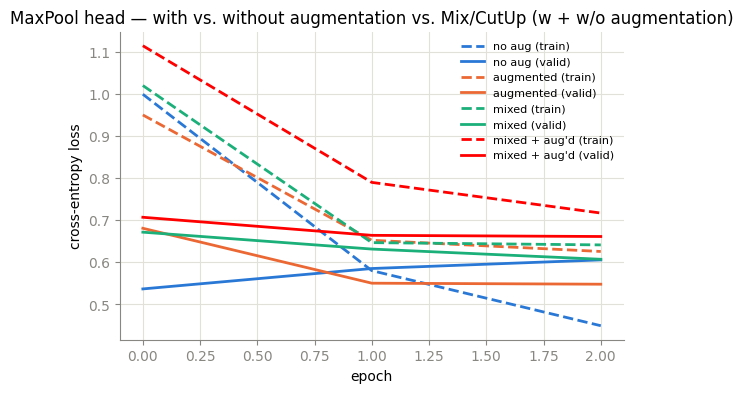

No augmentation -> final valid acc: 0.690
With augmentation -> final valid acc: 0.710
MixedCut without augmentation -> final valid acc: 0.730
MixedCut with augmentation -> final valid acc: 0.590


In [37]:
best_model_class = pooling_strategies[best_head_name]

train_data_object_noaug = CustomTrainingData(train_df, CLASS_LIST, base_transform)
# num_workers=0 for the same macOS/notebook multiprocessing reason as train_loader above.
train_loader_noaug = DataLoader(train_data_object_noaug, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

train_data_object_aug = CustomTrainingData(train_df, CLASS_LIST, aug_transform)
train_loader_aug = DataLoader(train_data_object_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

train_loader_mixed = DataLoader(
    train_data_object_noaug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_with_mixing,
)

train_loader_mixed_aug = DataLoader(
    train_data_object_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_with_mixing,
)



torch.manual_seed(SEED)
model_noaug = best_model_class(model_name='efficientnet_b0', num_classes=2, pretrained=True)
model_noaug.backbone.requires_grad_(False)
model_noaug.backbone.eval()
hist_noaug = train_model(model_noaug, train_loader_noaug, test_loader, epochs=3)

torch.manual_seed(SEED)
model_aug = best_model_class(model_name='efficientnet_b0', num_classes=2, pretrained=True)
model_aug.backbone.requires_grad_(False)
model_aug.backbone.eval()
hist_aug = train_model(model_aug, train_loader_aug, test_loader, epochs=3)

torch.manual_seed(SEED)
model_mixed = best_model_class(model_name="efficientnet_b0",num_classes=2,pretrained=True,)
model_mixed.backbone.requires_grad_(False)
model_mixed.backbone.eval()
hist_mixed = train_model(model_mixed,train_loader_mixed,test_loader,epochs=3)

torch.manual_seed(SEED)
model_mixed_aug = best_model_class(model_name="efficientnet_b0",num_classes=2,pretrained=True,)
model_mixed_aug.backbone.requires_grad_(False)
model_mixed_aug.backbone.eval()
hist_mixed_aug = train_model(model_mixed_aug,train_loader_mixed_aug,test_loader,epochs=3)


fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(hist_noaug["train_loss"], color=PALETTE["blue"], linestyle="--", linewidth=2, label="no aug (train)")
ax.plot(hist_noaug["valid_loss"], color=PALETTE["blue"], linestyle="-", linewidth=2, label="no aug (valid)")
ax.plot(hist_aug["train_loss"], color=PALETTE["orange"], linestyle="--", linewidth=2, label="augmented (train)")
ax.plot(hist_aug["valid_loss"], color=PALETTE["orange"], linestyle="-", linewidth=2, label="augmented (valid)")
ax.plot(hist_mixed["train_loss"], color=PALETTE["aqua"], linestyle="--", linewidth=2, label="mixed (train)")
ax.plot(hist_mixed["valid_loss"], color=PALETTE["aqua"], linestyle="-", linewidth=2, label="mixed (valid)")
ax.plot(hist_mixed_aug["train_loss"], color='red', linestyle="--", linewidth=2, label="mixed + aug'd (train)")
ax.plot(hist_mixed_aug["valid_loss"], color='red', linestyle="-", linewidth=2, label="mixed + aug'd (valid)")

style_ax(ax)
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
ax.set_title(f"{best_head_name} head — with vs. without augmentation vs. Mix/CutUp (w + w/o augmentation)")
ax.legend(fontsize=8, frameon=False)
plt.show()

print(f"No augmentation -> final valid acc: {hist_noaug['valid_acc'][-1]:.3f}")
print(f"With augmentation -> final valid acc: {hist_aug['valid_acc'][-1]:.3f}")
print(f"MixedCut without augmentation -> final valid acc: {hist_mixed['valid_acc'][-1]:.3f}")
print(f"MixedCut with augmentation -> final valid acc: {hist_mixed_aug['valid_acc'][-1]:.3f}")




## Questions
* Use cutmix and mixup transformations
* Report the effects on training and validation scores. 

## Answers
* The validation accuracy increased when Cutmix and Mixup were used in combination with the unaugmented images.
* When Cutmix and Mixup were used in combination with the augmented images, the validation score of the model actually decreased.

## Bonus Question 
* Check the hugging face website for a big backbone model such as "convnext_large.fb_in22k_ft_in1k"
* Use a big backbone 
* What errors do you see
* Read on gradient checkpointing and implement that for the above exersice. 


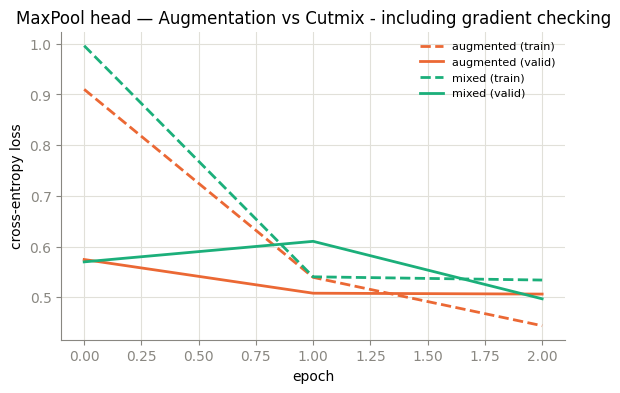

With augmentation -> final valid acc: 0.710
MixedCut without augmentation -> final valid acc: 0.730


In [38]:
torch.manual_seed(SEED)
model_aug_check = best_model_class(model_name='efficientnet_b0', num_classes=2, pretrained=True)
model_aug_check.backbone.requires_grad_(True)
model_aug_check.backbone.set_grad_checkpointing(True)
model_aug_check.backbone.eval()
hist_aug_check = train_model(model_aug_check, train_loader_aug, test_loader, epochs=3)

torch.manual_seed(SEED)
model_mixed_check = best_model_class(model_name="efficientnet_b0",num_classes=2,pretrained=True,)
model_mixed_check.backbone.requires_grad_(True)
model_mixed_check.backbone.set_grad_checkpointing(True)
model_mixed_check.backbone.eval()
hist_mixed_check = train_model(model_mixed_check,train_loader_mixed,test_loader,epochs=3)

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(hist_aug_check["train_loss"], color=PALETTE["orange"], linestyle="--", linewidth=2, label="augmented (train)")
ax.plot(hist_aug_check["valid_loss"], color=PALETTE["orange"], linestyle="-", linewidth=2, label="augmented (valid)")
ax.plot(hist_mixed_check["train_loss"], color=PALETTE["aqua"], linestyle="--", linewidth=2, label="mixed (train)")
ax.plot(hist_mixed_check["valid_loss"], color=PALETTE["aqua"], linestyle="-", linewidth=2, label="mixed (valid)")

style_ax(ax)
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
ax.set_title(f"{best_head_name} head — Augmentation vs Cutmix - including gradient checking")
ax.legend(fontsize=8, frameon=False)
plt.show()


print(f"With augmentation -> final valid acc: {hist_aug['valid_acc'][-1]:.3f}")
print(f"MixedCut without augmentation -> final valid acc: {hist_mixed['valid_acc'][-1]:.3f}")

## Answers 
* While the training cross entropy loss for this backbone is very low, the model is severely ovefitted. The validation set has a loss of close to 1, showing that it does not generalise well.

In [39]:
torch.manual_seed(SEED)

convnext_model = CustomTimmModel(
    model_name="convnext_large.fb_in22k_ft_in1k",
    num_classes=2,
    pretrained=True,
)

# Start by training only your classification head
convnext_model.backbone.requires_grad_(False)

convnext_train_loader = DataLoader(
    train_data_object,
    batch_size=4,
    shuffle=True,
    num_workers=0,
)

convnext_valid_loader = DataLoader(
    test_data_object,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

convnext_history = train_model(
    convnext_model,
    convnext_train_loader,
    convnext_valid_loader,
    epochs=3,
    lr=1e-3,
)

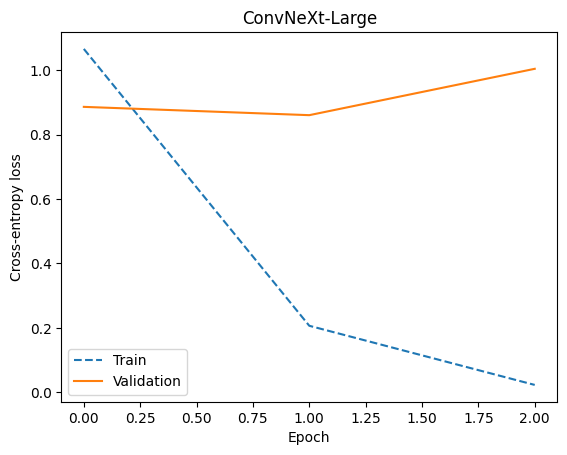

In [40]:
plt.plot(convnext_history["train_loss"], "--", label="Train")
plt.plot(convnext_history["valid_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("ConvNeXt-Large")
plt.legend()
plt.show()

## Takeaways

- **Effect of pooling features.** 
- **Frozen vs training model** 
- **Augmentation** 

# Questions from Canvas

Data: CIFAR-10, cat vs. dog Question

    Check the stats of the dataset
    How many samples exist per category.

 
Exercise 1 — EfficientNet backbone + custom pooling heads
Questions

    What is dataloader
    What is the effect of batch size value,
    In the cell above what is the shape of sample_images, what does each dimension represent?
    Increase the number of training data and see the effect on the train/validation loss

Questions:

    Implement a new class similar to MinPoolTimmModel for max pooling.
    Observe the training and validation loss
    Compare the result with the currently implemented pooling heads.
    Check on the web what is the default pooling layer of the timm model
    Report your observations on the above questions

    Full fine-tuning vs. a frozen backbone
    Questions

        What could be the downsides of doing fine tuning of a pretrained model

 
Exercise 2 — Data augmentation
Questions

    Use cutmix and mixup transformations
    Report the effects on training and validation scores.



 
!!!Bonus Question!!!

    Check the hugging face website for a big backbone model such as "convnext_large.fb_in22k_ft_in1k"
    Use a big backbone
    What errors do you see
    Read on gradient checkpointing and implement that for the above exersice.
